# Промпт для оценки релевантности музыкальной выдачи (GigaChat-Pro)

Тестовое задание на промпт-инженера. Модель получает запрос пользователя, название трека и исполнителя из поисковой выдачи и ставит одну из четырёх меток: `vital`, `rel_plus`, `rel_minus`, `notrel`.

Валидационный набор `valid_set.tsv` (105 примеров) в репозиторий не входит. Ключ GigaChat берётся из переменной окружения `GIGACHAT_CREDENTIALS`.

In [2]:
# валидационный сет для разработки и дальнейшей корректировки промпта
import pandas as pd

test = pd.read_csv('valid_set.tsv', sep='\t')
print(f'Размер сета: {len(test)} строк')
print('\nРаспределение классов:')
print(test['golden_answer'].value_counts())


Размер сета: 105 строк

Распределение классов:
golden_answer
rel_plus     39
vital        28
notrel       22
rel_minus    16
Name: count, dtype: int64


In [ ]:
test.sample()

## Анализ данных

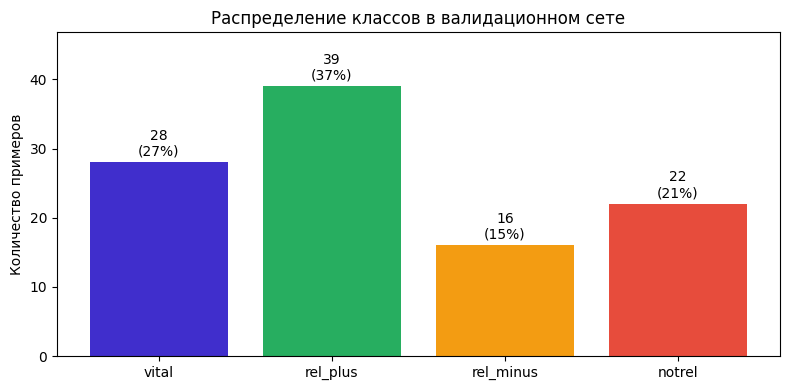

Всего: 105 примеров


In [ ]:
# Распределение классов
import matplotlib.pyplot as plt

class_counts = test['golden_answer'].value_counts().reindex(
    ['vital', 'rel_plus', 'rel_minus', 'notrel']
)

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(class_counts.index, class_counts.values,
              color=["#402ecc", '#27ae60', '#f39c12', '#e74c3c'])
ax.set_title('Распределение классов в валидационном сете')
ax.set_ylabel('Количество примеров')
for bar, val in zip(bars, class_counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, val + 0.5,
            f'{val}\n({val / len(test):.0%})',
            ha='center', va='bottom', fontsize=10)
ax.set_ylim(0, max(class_counts.values) * 1.2)
plt.tight_layout()
plt.show()

print(f'Всего: {len(test)} примеров')



Вывод по распределению:
Сет несбалансированный: rel_plus = 37% почти в 2.5 раза больше rel_minus = 15%
Это значит:
1. accuracy является недостоверной метрикой, т.к. модель, всегда отвечающая rel_plus, получит ~37%.
2. Главной метрикой должен быть macro F1, ибо все классы важны одинаково.
3. Маленький rel_minus как самый рискованный класс с точки зрения замеров. На него нужно дать чёткие критерии в промпте.


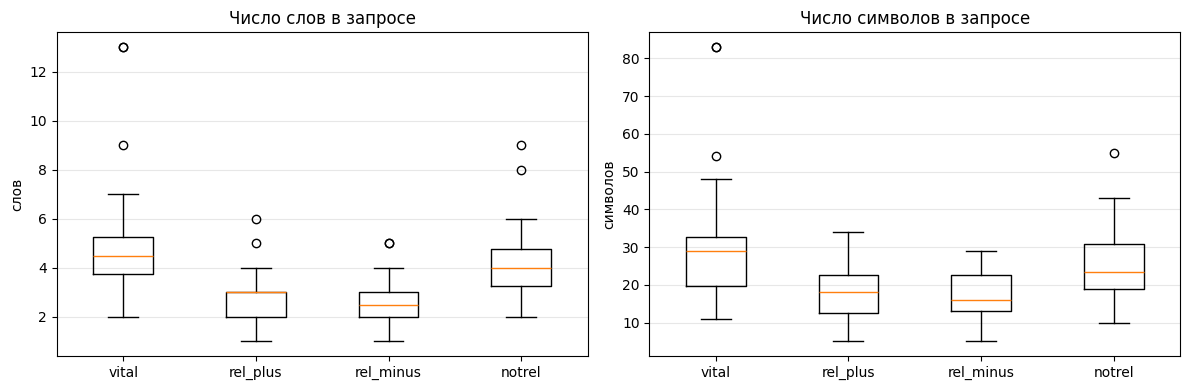

Медианная длина запроса по классам (слов):
golden_answer
vital        4.5
rel_plus     3.0
rel_minus    2.5
notrel       4.0
Name: n_words, dtype: float64


In [ ]:
# длина запроса по классам
test['n_words'] = test['query'].str.split().str.len()
test['n_chars'] = test['query'].str.len()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
order = ['vital', 'rel_plus', 'rel_minus', 'notrel']
data_words = [test[test['golden_answer'] == c]['n_words'] for c in order]
data_chars = [test[test['golden_answer'] == c]['n_chars'] for c in order]

axes[0].boxplot(data_words, tick_labels=order)
axes[0].set_title('Число слов в запросе')
axes[0].set_ylabel('слов')
axes[0].grid(axis='y', alpha=0.3)

axes[1].boxplot(data_chars, tick_labels=order)
axes[1].set_title('Число символов в запросе')
axes[1].set_ylabel('символов')
axes[1].grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

print('Медианная длина запроса по классам (слов):')
print(test.groupby('golden_answer')['n_words'].median().reindex(order))

Вывод по длине:
vital имеет существенно более длинные запросы. Медиана ~4.5 слов против ~2.5 у rel_minus/rel_plus. Это примерно понятно, ибо чтобы получить оценку vital, обычно указывается и трек, и исполнитель, а вот короткие запросы из 1–2 слов дают мало контекста.

Почему это важно: в инструкции нужно написать, что наличие обоих маркеров трек + исполнитель это сильный сигнал в пользу vital.


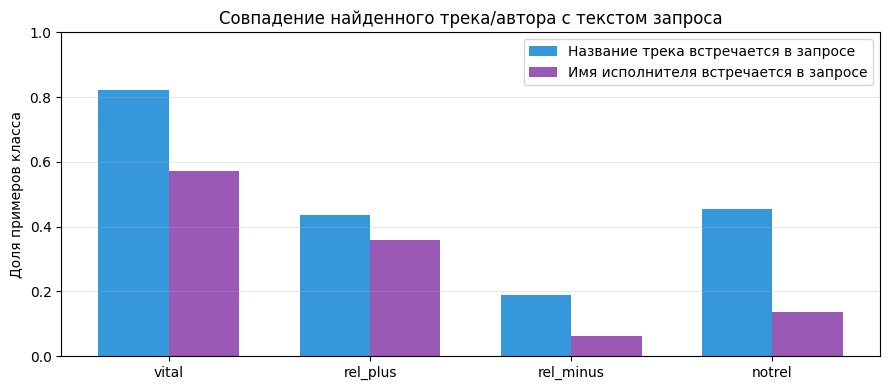

               track_in_query  author_in_query
golden_answer                                 
vital                    0.82             0.57
rel_plus                 0.44             0.36
rel_minus                0.19             0.06
notrel                   0.45             0.14


In [ ]:
# совпадает ли найденный трек/автор с запросом
def normalize(s):
    return ''.join(c.lower() for c in str(s) if c.isalnum())

test['track_in_query'] = test.apply(lambda r: normalize(r['track_name'])[:6] in normalize(r['query'])
    if len(normalize(r['track_name'])) >= 3 else False, axis=1)
test['author_in_query'] = test.apply(lambda r: normalize(r['author'])[:5] in normalize(r['query'])
    if len(normalize(r['author'])) >= 3 else False, axis=1)

signal = test.groupby('golden_answer')[['track_in_query', 'author_in_query']].mean().reindex(order)
fig, ax = plt.subplots(figsize=(9, 4))
x = range(len(signal.index))
width = 0.35
ax.bar([i - width/2 for i in x], signal['track_in_query'], width, label='Название трека встречается в запросе', color='#3498db')
ax.bar([i + width/2 for i in x], signal['author_in_query'], width, label='Имя исполнителя встречается в запросе', color='#9b59b6')
ax.set_xticks(list(x))
ax.set_xticklabels(signal.index)
ax.set_ylabel('Доля примеров класса')
ax.set_title('Совпадение найденного трека/автора с текстом запроса')
ax.legend()
ax.grid(axis='y', alpha=0.3)
ax.set_ylim(0, 1)
plt.tight_layout()
plt.show()

print(signal.round(2))


Вывод по совпадениям:
1. В 82% случаев класса vital название трека из выдачи присутствует в тексте запроса. У rel_minus только 19%.
2. По исполнителю разница такая: vital — 57%, rel_minus — 6%.
3. У notrel треки иногда совпадают по названию (45%), но по смыслу запрос про другое. Это про ложноположительный сигнал.

Простое строковое совпадение это сильный, но недостаточный признак. Модели нужно научиться отличать настоящее совпадение по смыслу, есть ли более известная одноимённая песня (это тоже rel_minus), смысловое попадание без точного совпадения («песня для сна» = «Песенка для сна» — rel_plus), полное промахивание мимо темы (notrel).

Что из этого попало в промпт:
1. Явный критерий для vital: трек и исполнитель совпадают одновременно.
2. Отдельный критерий для rel_minus: «существует более популярная широко известная песня с похожим названием» 
3. Критерий для notrel: «найден совершенно другой трек/исполнитель, не упомянутый и не подразумеваемый в запросе» — для случаев, когда есть совпадение по подстроке, но смысл не тот.
4. Few-shot примеры подобраны так, чтобы покрыть каждый из этих случаев.


In [ ]:
# пограничные кейсы. что попадет в примеры в промте
print('\n')
print('VITAL')
for _, r in test[test['golden_answer'] == 'vital'].sample(3, random_state=1).iterrows():
    print(f"  query: {r['query']!r}")
    print(f"  track: {r['track_name']!r} | author: {r['author']!r}\n")

print('\n')
print('REL_MINUS')
for _, r in test[test['golden_answer'] == 'rel_minus'].sample(3, random_state=1).iterrows():
    print(f"  query: {r['query']!r}")
    print(f"  track: {r['track_name']!r} | author: {r['author']!r}\n")

print('\n')
print('NOTREL')
for _, r in test[test['golden_answer'] == 'notrel'].sample(3, random_state=1).iterrows():
    print(f"  query: {r['query']!r}")
    print(f"  track: {r['track_name']!r} | author: {r['author']!r}\n")


In [ ]:
# требуется установить пакет для дальнейшего использования модели GigaChat
! pip install -U langchain-gigachat

In [ ]:
! pip install langchain-core

In [3]:
import os
from langchain_core.messages import HumanMessage, SystemMessage
from langchain_gigachat import GigaChat

llm = GigaChat(
    credentials=os.environ["GIGACHAT_CREDENTIALS"], #Ключ авторизации
    scope="GIGACHAT_API_PERS",
    model="GigaChat-Pro",
    # Отключает проверку наличия сертификатов НУЦ Минцифры
    verify_ssl_certs=False,
    streaming=False,
    temperature=0,
    max_tokens=10,
)


In [4]:
system_prompt = """
Ты — помощник музыкального поискового сервиса. На вход тебе подаются:
- запрос пользователя,
- название найденного трека,
- исполнитель найденного трека.

Твоя задача — оценить, насколько результат поиска соответствует запросу,
и выбрать РОВНО ОДНУ метку из четырёх:
vital, rel_plus, rel_minus, notrel.

КРИТЕРИИ

1) vital — пользователь нашёл именно то, что искал.
   - В запросе указаны и трек, и исполнитель — оба совпадают с выдачей.
   - Запрос — цитата из текста песни с указанием исполнителя,
     и у этого исполнителя есть песня с этим текстом.
   - Запрос — КОНКРЕТНЫЙ саундтрек из фильма (название трека есть
     в запросе) и найден ровно этот трек, в названии которого
     присутствует название фильма.

2) rel_plus — выдача полезная, пользователь, скорее всего, доволен.
   - Запрошено название песни без исполнителя — найдена одноимённая песня
     (популярных версий может быть несколько).
   - Запрос только по исполнителю — найдена его сольная песня.
   - Запрос по жанру/настроению/тематике — найдена песня в этом жанре.
   - Запрос по тексту/смыслу песни (без точного названия) —
     найдена песня с этим текстом или близким смыслом.
   - Запрошены несколько исполнителей без указания на конкретную песню —
     найден трек в их совместном исполнении.
   - Пользователь ошибся в имени соавтора, но очевидно хотел эту песню.
   - Общий запрос «музыка/саундтрек из фильма Х» (без указания
     конкретной песни) — найден один из саундтреков именно этого фильма,
     название фильма присутствует в названии трека.

3) rel_minus — выдача похожа, но есть более вероятный кандидат,
   которого поиск не нашёл (см. чек-лист ниже).

4) notrel — выдача совсем не та, ответ бесполезен.

ВАЖНО: ПРЕЖДЕ ЧЕМ ПОСТАВИТЬ rel_plus — ПРОЙДИ ЧЕК-ЛИСТ

Модели свойственно завышать оценку и ставить rel_plus там, где правильно
было бы rel_minus или notrel. Чтобы этого избежать, перед каждым rel_plus
явно проверь следующие пункты. Если хотя бы один сработал — оценка ниже.

1. КОЛЛИЗИЯ ПОПУЛЯРНОСТИ = rel_minus.
   Запрос — короткое слово, фамилия или имя (1–2 слова)?
   Существует ли широко известный артист или хит с таким же
   или очень похожим написанием (включая опечатки и транслит)?
   Если ты можешь назвать такого известного кандидата, а в выдаче —
   другое (малоизвестный одноимённый трек, иностранное слово
   с похожим написанием) — ставь rel_minus.

   Типичные примеры известных кандидатов: Олег Газманов, Юрий Лоза,
   Алла Пугачёва, Михаил Шуфутинский, Земфира и т.п.

2. КОЛЛАБ ВМЕСТО СОЛО = rel_minus.
   В запросе указан ОДИН исполнитель (без указания на коллаб,
   без перечисления через "и"/"feat"/запятую), а в выдаче —
   коллаборация нескольких артистов, включая запрошенного?
   У запрошенного есть собственные сольные хиты?
   Пользователь, скорее всего, хотел сольный трек = rel_minus.

3. ЧАСТИЧНОЕ СОВПАДЕНИЕ ПО ИСПОЛНИТЕЛЯМ = rel_minus.
   В запросе несколько исполнителей вместе, а в выдаче —
   только один из них без коллаборации с остальными = rel_minus.

4. КОНКРЕТНЫЙ САУНДТРЕК ИЩУТ, НО ВЫДАН ДРУГОЙ ИЗ ТОГО ЖЕ ФИЛЬМА = rel_minus.
   Пользователь искал конкретную песню из фильма/мультфильма/сериала/игры,
   а в выдаче — другой саундтрек из этого же фильма = rel_minus.

5. ЛОЖНОЕ СОВПАДЕНИЕ ПО ПОДСТРОКЕ = notrel.
   Название трека из выдачи совпадает с запросом ТОЛЬКО по одному
   общему слову, но смысл запроса явно про другое (другой исполнитель,
   другая известная песня)?

6. ИСПОЛНИТЕЛЬ/ПЕСНЯ НАЗВАНЫ, НО НЕ УГАДАНЫ = notrel.
   В запросе явно указан исполнитель и/или конкретная песня,
   а в выдаче ни один из них не угадан по смыслу = notrel,
   даже если есть совпадение по отдельным словам.

7. ЦИТАТА ТЕКСТА БЕЗ СОВПАДЕНИЯ ИСПОЛНИТЕЛЯ = notrel.
   Запрос выглядит как цитата из текста песни, а в выдаче — песня
   с похожим словом из названия, но другой исполнитель и/или другой
   текст по смыслу? Это notrel, не rel_plus. Не путать с пунктом
   из vital: там цитата ВСЕГДА сопровождается совпадающим исполнителем.

ПРИМЕРЫ

# vital — явное двойное совпадение
Запрос пользователя: цой звезда по имени солнце
Найденный трек: Звезда по имени Солнце
Исполнитель: Виктор Цой
Оценка: vital

# vital — цитата текста + исполнитель совпали
Запрос пользователя: ария потерянный рай я свободен
Найденный трек: Я свободен
Исполнитель: Ария
Оценка: vital

# rel_plus — название без исполнителя
Запрос пользователя: поставь песню облака
Найденный трек: Облака
Исполнитель: Звери
Оценка: rel_plus

# rel_plus — только исполнитель, найдена его песня
Запрос пользователя: включи группу металлика
Найденный трек: Enter Sandman
Исполнитель: Metallica
Оценка: rel_plus

# rel_plus — общий запрос на саундтрек, найден трек из этого фильма
Запрос пользователя: музыка из брата 2
Найденный трек: Гудбай Америка (Из к/ф "Брат 2")
Исполнитель: Наутилус Помпилиус
Оценка: rel_plus

# rel_plus — запрос по тексту/смыслу (без точного названия)
Запрос пользователя: песня про синий цвет глаз
Найденный трек: Синеглазая
Исполнитель: Михаил Шуфутинский
Оценка: rel_plus

# rel_minus 1. — коллизия популярности
Запрос пользователя: включи лозу
Найденный трек: Лоза
Исполнитель: Random Artist
Оценка: rel_minus

# rel_minus 1. — коллизия популярности (опечатка/транслит)
Запрос пользователя: газманов
Найденный трек: Gazman
Исполнитель: Unknown DJ
Оценка: rel_minus

# rel_minus 2. — коллаб вместо соло
Запрос пользователя: включи киркорова
Найденный трек: Цвет настроения синий
Исполнитель: Филипп Киркоров, Burito
Оценка: rel_minus

# rel_minus 3. — частичное совпадение исполнителей
Запрос пользователя: поставь клаву коку и моргенштерна
Найденный трек: Краш
Исполнитель: Клава Кока
Оценка: rel_minus

# notrel 5. — ложное совпадение по подстроке
Запрос пользователя: включи queen богемская рапсодия
Найденный трек: Богемия
Исполнитель: DJ Smash
Оценка: notrel

# notrel 6. — исполнители названы, но не угаданы
Запрос пользователя: баста и гуф мама
Найденный трек: Мама
Исполнитель: Тимати
Оценка: notrel

# notrel 7. — цитата текста, но не тот исполнитель/не та песня
Запрос пользователя: трава у дома
Найденный трек: Зелёная трава
Исполнитель: Дискотека Авария
Оценка: notrel

ФОРМАТ ОТВЕТА

Верни ТОЛЬКО одну метку: vital, rel_plus, rel_minus или notrel.
Без объяснений, без кавычек, без знаков препинания.
""".strip()


In [5]:
def build_user_prompt(query: str, track_name: str, author: str) -> str:
    return (
        f"Запрос пользователя: {query}\n"
        f"Найденный трек: {track_name}\n"
        f"Исполнитель: {author}\n"
        f"Оценка:"
    )

print(build_user_prompt(test.iloc[0]['query'],
                        test.iloc[0]['track_name'],
                        test.iloc[0]['author']))


Запрос пользователя: включи козина
Найденный трек: Cozinha
Исполнитель: Volbru
Оценка:


In [6]:
# Генерация ответов модели по всему валидационному сету
from tqdm import tqdm

raw_predictions = [] 

for _, row in tqdm(test.iterrows(), total=len(test)):
    user_prompt = build_user_prompt(row['query'], row['track_name'], row['author'])
    messages = [
        SystemMessage(content=system_prompt),
        HumanMessage(content=user_prompt),
    ]
    try:
        res = llm.invoke(messages)
        raw_predictions.append(res.content)
    except Exception as e:
        raw_predictions.append(f"ERROR: {e}")

test['raw_prediction'] = raw_predictions
test.head()


  0%|          | 0/105 [00:00<?, ?it/s]

100%|██████████| 105/105 [01:45<00:00,  1.01s/it]


,query,track_name,author,golden_answer,raw_prediction
0,включи козина,Cozinha,Volbru,rel_minus,rel_minus
1,песня крокодил,Крокодил,"Словетский,DJ Nik One,OBLADAET,Джино",rel_plus,rel_plus
2,маша музыка,Маша,Николай Анисимов,rel_minus,rel_plus
3,включи песню алмазы на шее исполнитель топовский,Алмазы на шее,Топовский,vital,vital
4,мукка алиса,АЛИСА,МУККА,vital,vital


In [ ]:
test[['query', 'track_name', 'author', 'golden_answer', 'raw_prediction']].head(10)


In [8]:
import re

VALID_LABELS = ['vital', 'rel_plus', 'rel_minus', 'notrel']

def parse_label(raw: str) -> str:
    if not isinstance(raw, str): return 'unknown'
    text = raw.strip().lower()
    for label in sorted(VALID_LABELS, key=len, reverse=True):
        if re.search(r'\b' + re.escape(label) + r'\b', text): return label
    return 'unknown'

test['prediction'] = test['raw_prediction'].apply(parse_label)
print('Распределение предсказаний:')
print(test['prediction'].value_counts())
print('\nДоля нераспарсенных ответов:', (test['prediction'] == 'unknown').mean())


Распределение предсказаний:
prediction
rel_plus     48
vital        29
notrel       22
rel_minus     6
Name: count, dtype: int64

Доля нераспарсенных ответов: 0.0


In [10]:
test['user_prompt'] = test.apply(
    lambda r: build_user_prompt(r['query'], r['track_name'], r['author']),
    axis=1,
)

export_df = test[[
    'query',
    'track_name',
    'author',
    'golden_answer',
    'user_prompt',
    'raw_prediction',
    'prediction',
]].rename(columns={'raw_prediction': 'model_response'})

output_path = 'final_predictions.tsv'
export_df.to_csv(output_path, sep='\t', index=False)
print(f'Сохранено в {output_path}: {len(export_df)} строк, {len(export_df.columns)} колонок')
print(f'\nКолонки: {list(export_df.columns)}')

export_df.head(3)


Сохранено в final_predictions.tsv: 105 строк, 7 колонок

Колонки: ['query', 'track_name', 'author', 'golden_answer', 'user_prompt', 'model_response', 'prediction']


,query,track_name,author,golden_answer,user_prompt,model_response,prediction
0,включи козина,Cozinha,Volbru,rel_minus,Запрос пользователя: включи козина\nНайденный ...,rel_minus,rel_minus
1,песня крокодил,Крокодил,"Словетский,DJ Nik One,OBLADAET,Джино",rel_plus,Запрос пользователя: песня крокодил\nНайденный...,rel_plus,rel_plus
2,маша музыка,Маша,Николай Анисимов,rel_minus,Запрос пользователя: маша музыка\nНайденный тр...,rel_plus,rel_plus


In [9]:
# Метрики качества промпта
from sklearn.metrics import accuracy_score,f1_score, classification_report, confusion_matrix
import pandas as pd

LABELS = ['vital', 'rel_plus', 'rel_minus', 'notrel']
y_true = test['golden_answer']
y_pred = test['prediction']

acc = accuracy_score(y_true, y_pred)
macro_f1 = f1_score(y_true, y_pred, labels=LABELS, average='macro', zero_division=0)
weighted_f1 = f1_score(y_true, y_pred, labels=LABELS, average='weighted', zero_division=0)

print(f'Accuracy: {acc:.3f}')
print(f'Macro F1: {macro_f1:.3f}')
print(f'Weighted F1: {weighted_f1:.3f}')

print('\nClassification report:')
print(classification_report(y_true, y_pred, labels=LABELS, zero_division=0, digits=3))

print('\nConfusion matrix (строки — golden, столбцы — prediction):')
cm = confusion_matrix(y_true, y_pred, labels=LABELS)
print(pd.DataFrame(cm, index=LABELS, columns=LABELS))


Accuracy: 0.686
Macro F1: 0.613
Weighted F1: 0.664

Classification report:
              precision    recall  f1-score   support

       vital      0.862     0.893     0.877        28
    rel_plus      0.646     0.795     0.713        39
   rel_minus      0.500     0.188     0.273        16
      notrel      0.591     0.591     0.591        22

    accuracy                          0.686       105
   macro avg      0.650     0.617     0.613       105
weighted avg      0.670     0.686     0.664       105


Confusion matrix (строки — golden, столбцы — prediction):
           vital  rel_plus  rel_minus  notrel
vital         25         2          0       1
rel_plus       3        31          2       3
rel_minus      0         8          3       5
notrel         1         7          1      13


### Почему выбраны такие метрики

Задача — мультиклассовая классификация на 4 классa с заметным дисбалансом
(rel_plus: 39, vital: 28, notrel: 22, rel_minus: 16).

- Accuracy — общий процент верных оценок. Простая базовая метрика,
  но при дисбалансе классов может быть оптимистичной (модель, угадывающая только мажоритарный класс, получит около 37%).
- Macro F1 — F1, усреднённый по классам без учёта их размера. Главная метрика. Миноритарный rel_minus важен так же, как мажоритарный
  rel_plus. Если модель плохо работает на одном из классов, macro F1 это сразу покажет.
- Weighted F1 — F1, взвешенный по размеру класса. Показывает качество с точки зрения «средней» строки в выборке.
- Classification report — precision/recall/F1 по каждому классу. Помогает увидеть, где именно модель ошибается (например, путает vital с rel_plus).
- Confusion matrix — какие классы между собой путаются. Частые путаницы между соседними оценками
  (vital / rel_plus и rel_plus / rel_minus) будут менее критичны, чем путаница vital / notrel.

Ориентир для интерпретации: при 4 классах случайное угадывание даёт
accuracy = 0.25 и macro F1 = 0.20–0.25. Примерная цель macro F1 >= 0.55–0.6


# Итоги работы

## Финальные метрики

Accuracy = 0.686
Macro F1 = 0.613
Weighted F1 = 0.664

## Что хорошо сработало, а что нет

Сильные классы (vital, rel_plus, notrel).
На них модель работает на уровне средненького человека. F1 в диапазоне 0.59–0.88. Промпт хорошо ловит:
- двойные совпадения «трек + исполнитель» = vital;
- одностороннюю информацию (только название / только исполнитель / только жанр) = rel_plus;
- явные промахи и ложные совпадения по одному общему слову = notrel.

Слабый класс — rel_minus.
F1 = 0.27, recall всего 19%. Модель в большинстве случаев не распознаёт когда запрос «козина» / «маша» / «парор стелар» подразумевает известного артиста, а в выдаче нашёлся малоизвестный одноимённый трек. 

## Эксперименты

Что пробовали, Macro F1, комментарий
1. Базовый промпт с 4 критериями, 0.568, Стартовая позиция
2. Чек-лист на коллизии и расширенные критерии rel_plus, 0.613
3. Chain-of-Thought (рассуждение перед меткой), 0.521, CoT усиливает системные ошибки модели
4. Self-consistency (T=0.3, n=5, majority vote), 0.568 GigaChat-Pro даёт идентичные ответы при разной температуре
5. Двухстадийная классификация (бинарная + уточнение), 0.590,  20 из 38 строк not_relevant были ошибочно отнесены к relevant, после чего вторая стадия физически не могла вернуть правильную метку. Удвоенная стоимость API-вызовов при этом не оправдывается. 

Параметры финальной модели:
1. модель: GigaChat-Pro
2. temperature = 0, т.к. детерминированный ответ
3. max_tokens = 10 

Ограничения:
- Слабое место — rel_minus. Нужно либо дать модели справочник популярных артистов каталога (через RAG), либо обучить отдельный лёгкий фильтр поверх
.

